# Modelos Avançados e Ensemble Final
Foco: integração e seleção do melhor modelo final

### Carregamento de features estáticas e temporais

c:\Python312\Lib\site-packages\keras\src\layers\core\masking.py:47: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [23:24:02] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


c:\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [23:24:33] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
### Resultados Tabulares ###
          recall  accuracy
LR         0.931     0.916
RF         0.897     0.996
XGB        0.966     0.995
FNN        0.914     0.996
Ensemble   0.948     0.994

### Resultados Sequenciais ###
      recall  accuracy
LSTM     1.0       1.0


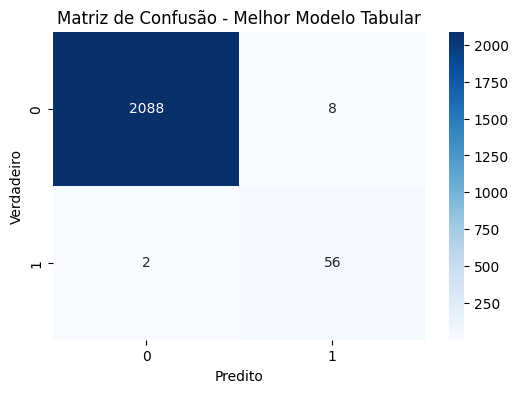

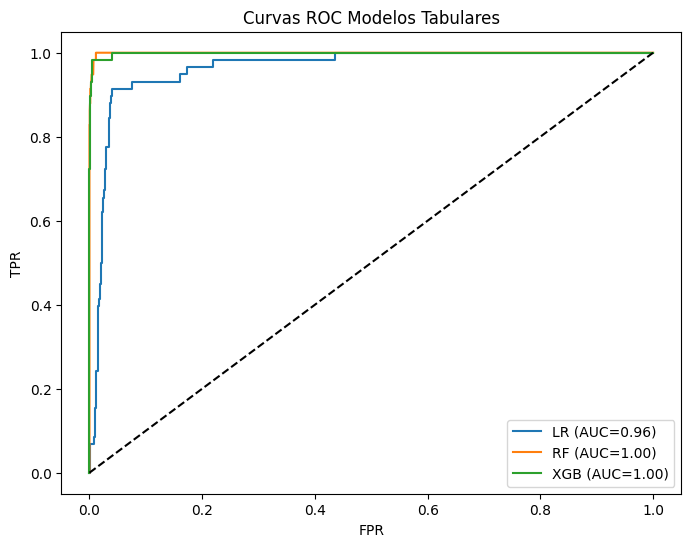

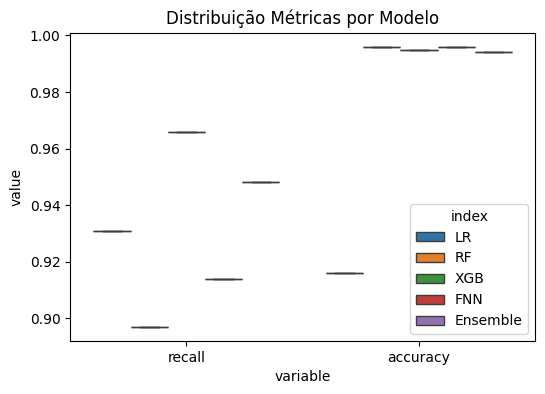

68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  

### FNN com Focal Loss ###
           recall  accuracy
LR          0.931     0.916
RF          0.897     0.996
XGB         0.966     0.995
FNN         0.914     0.996
Ensemble    0.948     0.994
FNN-Focal   0.190     0.978


In [17]:

# 04_final_ensemble_and_evaluation.ipynb
# Notebook 4 — Modelos Avançados e Ensemble Final
# Foco: integração e seleção do melhor modelo final com visualizações detalhadas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
import xgboost as xgb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Masking, LSTM
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import recall_score, accuracy_score, classification_report, confusion_matrix, roc_curve, auc
import tensorflow.keras.backend as K
import tensorflow as tf

# --- Focal Loss customizada ---
def focal_loss(alpha=0.25, gamma=2.0):
    def loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        pt = tf.where(tf.equal(y_true, 1), y_pred, 1 - y_pred)
        ce = -K.log(pt + K.epsilon())
        weight = alpha * K.pow(1 - pt, gamma)
        return K.mean(weight * ce)
    return loss

# Parâmetros
TEST_SIZE = 0.2
RND_STATE = 42
TIMESTEP = 5
ES = EarlyStopping(patience=5, restore_best_weights=True)

# 1) Carregar dados tabular e sequencial
# --------------------------------------
df_tab = pd.read_csv("../csv/train_data_features.csv")
df_seq = pd.read_csv("../csv/train_data_filtered.csv")

y_tab = (df_tab['risk'] >= -6).astype(int)
y_seq_event = df_seq.groupby('event_id')['risk'].last().apply(lambda v: int(v >= -6))

# 2) Split por event_id para garantir correspondência
event_ids = df_tab['event_id'].unique()
train_ids, test_ids = train_test_split(event_ids, test_size=TEST_SIZE,
                                       stratify=y_tab, random_state=RND_STATE)

# 3) Prepara X_tab (drop infinities e NaNs)
X_tab = df_tab.drop(['event_id', 'risk'], axis=1)
X_tab = X_tab.replace([np.inf, -np.inf], np.nan)
X_tab = X_tab.fillna(X_tab.median())

mask_tab_tr = df_tab['event_id'].isin(train_ids)
mask_tab_te = df_tab['event_id'].isin(test_ids)
X_tab_tr, X_tab_te = X_tab[mask_tab_tr], X_tab[mask_tab_te]
y_tr, y_te = y_tab[mask_tab_tr], y_tab[mask_tab_te]

# 4) Prepara X_seq (tensor 3D) alinhado ao split
feat_cols = df_seq.columns.difference(['event_id', 'risk'])
seq_ids = y_seq_event.index.values

# monta array
X_seq_arr = np.zeros((len(seq_ids), TIMESTEP, len(feat_cols)))
for i, eid in enumerate(seq_ids):
    data = df_seq[df_seq['event_id']==eid][feat_cols].values
    L = data.shape[0]
    if L >= TIMESTEP:
        X_seq_arr[i] = data[-TIMESTEP:]
    else:
        X_seq_arr[i, -L:] = data

# define máscaras para sequencial
mask_seq_tr = np.isin(seq_ids, train_ids)
mask_seq_te = np.isin(seq_ids, test_ids)
X_seq_tr = X_seq_arr[mask_seq_tr]
X_seq_te = X_seq_arr[mask_seq_te]

y_seq = y_seq_event.loc[seq_ids].values
y_seq_tr = y_seq[mask_seq_tr]
y_seq_te = y_seq[mask_seq_te]

# 5) Escalar dados tabulares
scaler = StandardScaler().fit(X_tab_tr)
X_tab_tr_s = scaler.transform(X_tab_tr)
X_tab_te_s = scaler.transform(X_tab_te)

# 6) Definir modelos
lr = LogisticRegression(class_weight='balanced', max_iter=500)
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=RND_STATE)
scale = np.bincount(y_tr)[0] / np.bincount(y_tr)[1]
xgb_clf = xgb.XGBClassifier(n_estimators=100, scale_pos_weight=scale,
                             use_label_encoder=False, eval_metric='logloss',
                             random_state=RND_STATE)

fnn_tab = Sequential([
    Input(shape=(X_tab_tr_s.shape[1],)),
    Dense(64, activation='relu'), Dropout(0.3),
    Dense(32, activation='relu'), Dropout(0.2),
    Dense(1, activation='sigmoid')
])
fnn_tab.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy','Recall'])

lstm = Sequential([
    Masking(mask_value=0.0, input_shape=(TIMESTEP, len(feat_cols))),
    LSTM(64), Dropout(0.3), Dense(1, activation='sigmoid')
])
lstm.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy','Recall'])

# 7) Treino de todos os modelos
lr.fit(X_tab_tr_s, y_tr)
rf.fit(X_tab_tr_s, y_tr)
xgb_clf.fit(X_tab_tr_s, y_tr)
fnn_tab.fit(X_tab_tr_s, y_tr, validation_split=0.2,
            epochs=30, batch_size=32, callbacks=[ES], verbose=0)
lstm.fit(X_seq_tr, y_seq_tr, validation_split=0.2,
         epochs=30, batch_size=32, callbacks=[ES], verbose=0)

# 8) Predições e ensemble
preds_tab = {
    'LR': lr.predict(X_tab_te_s),
    'RF': rf.predict(X_tab_te_s),
    'XGB': xgb_clf.predict(X_tab_te_s),
    'FNN': (fnn_tab.predict(X_tab_te_s) > 0.5).astype(int).ravel()
}
en_tab = VotingClassifier(estimators=[('lr', lr), ('rf', rf), ('xgb', xgb_clf)],
                          voting='soft', weights=[1,1,2])
en_tab.fit(X_tab_tr_s, y_tr)
preds_tab['Ensemble'] = en_tab.predict(X_tab_te_s)

preds_seq = {'LSTM': (lstm.predict(X_seq_te) > 0.5).astype(int).ravel()}

# 9) Avaliação das métricas principais
def compute_metrics(y_true, y_pred):
    return {'recall': recall_score(y_true, y_pred),
            'accuracy': accuracy_score(y_true, y_pred)}
metrics_tab = {name: compute_metrics(y_te, pred)
               for name, pred in preds_tab.items()}
metrics_seq = {name: compute_metrics(y_seq_te, pred)
               for name, pred in preds_seq.items()}

# 10) Exibir resultados em tabelas
tab = pd.DataFrame(metrics_tab).T.round(3)
seq = pd.DataFrame(metrics_seq).T.round(3)
print("### Resultados Tabulares ###")
print(tab)
print("\n### Resultados Sequenciais ###")
print(seq)

# 11) Visualizações relevantes
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_te, preds_tab[tab['recall'].idxmax()]),
            annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusão - Melhor Modelo Tabular')
plt.xlabel('Predito'); plt.ylabel('Verdadeiro'); plt.show()

plt.figure(figsize=(8,6))
for name, model in [('LR', lr), ('RF', rf), ('XGB', xgb_clf)]:
    prob = model.predict_proba(X_tab_te_s)[:,1]
    fpr, tpr, _ = roc_curve(y_te, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr,tpr):.2f})")
plt.plot([0,1],[0,1],'k--')
plt.title('Curvas ROC Modelos Tabulares')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend(); plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(data=tab.reset_index().melt(id_vars='index',
            value_vars=['recall','accuracy']),
            x='variable', y='value', hue='index')
plt.title('Distribuição Métricas por Modelo'); plt.show()

# 12) FNN com Focal Loss
fnn_focal = Sequential([
    Input(shape=(X_tab_tr_s.shape[1],)),
    Dense(64, activation='relu'), Dropout(0.3),
    Dense(32, activation='relu'), Dropout(0.2),
    Dense(1, activation='sigmoid')
])
fnn_focal.compile(optimizer='adam', loss=focal_loss(), metrics=['accuracy','Recall'])
fnn_focal.fit(X_tab_tr_s, y_tr, validation_split=0.2,
              epochs=30, batch_size=32, callbacks=[ES], verbose=0)
pf = (fnn_focal.predict(X_tab_te_s) > 0.5).astype(int).ravel()
metrics_tab['FNN-Focal'] = compute_metrics(y_te, pf)
print("\n### FNN com Focal Loss ###")
print(pd.DataFrame(metrics_tab).T[['recall','accuracy']].round(3))
